MLP (2 layers) run 3/3: 100%|██████████| 3000/3000 [00:01<00:00, 2274.47it/s, loss=0.08447]


saved results\test8_robustness.png
saved results\test8_robustness.pdf


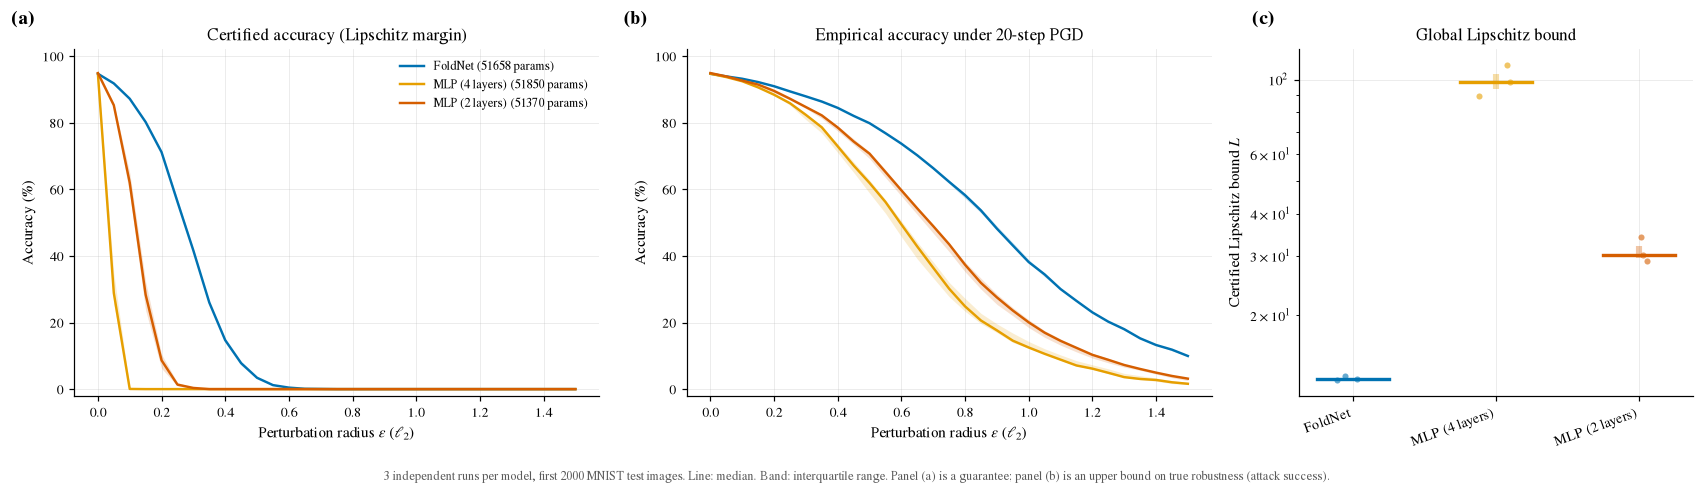

| $\varepsilon$ | Model | Lipschitz bound $L$ | Certified acc. (%) | PGD acc. (%) | Certification gap (pp) |
|---|---|---|---|---|---|
| 0.00 | FoldNet | 12.9 [12.9, 13.1] | 94.7 [94.7, 94.9] | 94.7 [94.7, 94.9] | 0.0 |
|  | MLP (4 layers) | 98.1 [93.9, 104.2] | 94.7 [94.7, 94.8] | 94.7 [94.7, 94.8] | 0.0 |
|  | MLP (2 layers) | 30.1 [29.5, 32.2] | 94.9 [94.7, 95.3] | 94.9 [94.7, 95.3] | 0.0 |
| 0.25 | FoldNet | 12.9 [12.9, 13.1] | 56.2 [55.7, 57.2] | 89.4 [89.3, 89.5] | 33.3 |
|  | MLP (4 layers) | 98.1 [93.9, 104.2] | 0.0 [0.0, 0.0] | 85.9 [85.3, 86.0] | 85.9 |
|  | MLP (2 layers) | 30.1 [29.5, 32.2] | 1.4 [1.0, 1.9] | 87.2 [86.9, 87.3] | 85.2 |
| 0.50 | FoldNet | 12.9 [12.9, 13.1] | 3.4 [3.2, 3.7] | 79.9 [79.7, 80.0] | 76.7 |
|  | MLP (4 layers) | 98.1 [93.9, 104.2] | 0.0 [0.0, 0.0] | 61.9 [58.9, 62.8] | 61.9 |
|  | MLP (2 layers) | 30.1 [29.5, 32.2] | 0.0 [0.0, 0.0] | 70.7 [69.2, 71.3] | 70.7 |
| 1.00 | FoldNet | 12.9 [12.9, 13.1] | 0.0 [0.0, 0.0] | 38.2 [38.0, 38.9] | 38.2 |
|  | 

In [1]:
"""Test 8: l2 robustness on MNIST. Certified accuracy (Lipschitz margin) vs empirical PGD accuracy."""
import math

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

from foldnet_lib import FoldNetClassifier, MLPClassifier, n_params, train_with_loader, DEV
from foldnet_bench import match_budget, seed_all
import foldnet_viz as V

D = 64                           # FoldNet width; baselines are parameter-matched
N_RUNS = 3
STEPS = 3000
BATCH = 128
N_EVAL = 2000                    # first test images used for certification and attack
EPS = np.linspace(0.0, 1.5, 31)  # l2 radii
EPS_TABLE = [0.0, 0.25, 0.5, 1.0, 1.5]
PGD_STEPS = 20
MARGIN_FACTOR = math.sqrt(2)     # |(f_i - f_j)(x) - (f_i - f_j)(x')| <= sqrt(2) L ||x - x'||
NAMES = ["FoldNet", "MLP (4 layers)", "MLP (2 layers)"]
RESULTS_DIR = "results"
V.COLORS.setdefault("MLP (4 layers)", "#E69F00")
V.COLORS.setdefault("MLP (2 layers)", "#D55E00")


def load_mnist(root="./data"):
    tr = datasets.MNIST(root, train=True, download=True)
    te = datasets.MNIST(root, train=False, download=True)
    Xtr = tr.data.float().div(255).view(-1, 784).to(DEV)
    Xte = te.data.float().div(255).view(-1, 784).to(DEV)
    return Xtr, tr.targets.to(DEV), Xte, te.targets.to(DEV)


@torch.no_grad()
def certified_lip(model):
    """Global l2 Lipschitz upper bound: ||W_in|| ||W_out|| for FoldNet (Theorem 3.4(c)),
    product of layer spectral norms for the MLPs."""
    sp = lambda w: torch.linalg.matrix_norm(w, ord=2).item()
    if isinstance(model, FoldNetClassifier):
        return sp(model.inp.weight) * sp(model.out.weight)
    L = 1.0
    for layer in model.net:
        if isinstance(layer, nn.Linear):
            L *= sp(layer.weight)
    return L


@torch.no_grad()
def certified_radii(model, X, y, L):
    """Per-sample certified l2 radius: margin / (sqrt(2) L) if correct, -1 otherwise."""
    logits = model(X)
    top2 = logits.topk(2, dim=1).values
    r = (top2[:, 0] - top2[:, 1]) / (MARGIN_FACTOR * L)
    return torch.where(logits.argmax(1) == y, r, torch.full_like(r, -1.0)).cpu().numpy()


def pgd_l2(model, X, y, eps, steps=PGD_STEPS):
    """l2 PGD with inputs clipped to [0, 1]."""
    if eps == 0.0:
        return X
    alpha = 2.5 * eps / steps
    x_adv = X.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        g, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        g = g / (g.flatten(1).norm(dim=1).view(-1, 1) + 1e-12)
        delta = x_adv.detach() + alpha * g - X
        norm = delta.flatten(1).norm(dim=1).view(-1, 1).clamp(min=1e-12)
        delta = delta * torch.clamp(eps / norm, max=1.0)
        x_adv = (X + delta).clamp(0.0, 1.0)
    return x_adv.detach()


@torch.no_grad()
def acc(model, X, y):
    return (model(X).argmax(1) == y).float().mean().item()


if __name__ == "__main__":
    V.set_style()
    Xtr, ytr, Xte, yte = load_mnist()
    Xs, ys = Xte[:N_EVAL], yte[:N_EVAL]

    target = n_params(FoldNetClassifier(784, 10, D, 4, 2))
    builders = {
        "FoldNet":        lambda: FoldNetClassifier(784, 10, D, 4, 2),
        "MLP (4 layers)": lambda: match_budget(lambda w: MLPClassifier(784, 10, w, 4), target, 4, 1024),
        "MLP (2 layers)": lambda: match_budget(lambda w: MLPClassifier(784, 10, w, 2), target, 4, 1024),
    }

    cert = {n: [] for n in NAMES}
    pgd = {n: [] for n in NAMES}
    lip = {n: [] for n in NAMES}
    npar = {}
    for n in NAMES:
        for r in range(N_RUNS):
            seed_all(r)
            m = builders[n]()
            train_with_loader(m, Xtr, ytr, steps=STEPS, batch=BATCH, lr=1e-3,
                              desc=f"{n} run {r + 1}/{N_RUNS}")
            m.eval()
            npar[n] = n_params(m)
            L = certified_lip(m)
            radii = certified_radii(m, Xs, ys, L)
            lip[n].append(L)
            cert[n].append([float((radii > e).mean()) for e in EPS])
            pgd[n].append([acc(m, pgd_l2(m, Xs, ys, float(e)), ys) for e in EPS])
    cert = {n: 100 * np.array(v) for n, v in cert.items()}     # (runs, n_eps), in %
    pgd = {n: 100 * np.array(v) for n, v in pgd.items()}

    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3), gridspec_kw=dict(width_ratios=[1.2, 1.2, 0.9]))
    for ax, data, title, letter in [(axes[0], cert, "Certified accuracy (Lipschitz margin)", "(a)"),
                                    (axes[1], pgd, f"Empirical accuracy under {PGD_STEPS}-step PGD", "(b)")]:
        for n in NAMES:
            V.band(ax, EPS, data[n], V.color_for(n), label=f"{n} ({npar[n]} params)")
        ax.set_xlabel(r"Perturbation radius $\varepsilon$ ($\ell_2$)")
        ax.set_ylabel("Accuracy (%)")
        ax.set_ylim(-2, 102)
        ax.set_title(title)
        V.panel_label(ax, letter)
    axes[0].legend(fontsize=8)

    V.strip(axes[2], NAMES, [lip[n] for n in NAMES], {n: V.color_for(n) for n in NAMES})
    axes[2].set_yscale("log")
    axes[2].set_ylabel("Certified Lipschitz bound $L$")
    axes[2].set_title("Global Lipschitz bound")
    V.panel_label(axes[2], "(c)")

    fig.text(0.5, -0.03, f"{N_RUNS} independent runs per model, first {N_EVAL} MNIST test images. "
             "Line: median. Band: interquartile range. Panel (a) is a guarantee; panel (b) is an "
             "upper bound on true robustness (attack success).",
             ha="center", fontsize=8, color="0.35")
    plt.tight_layout()
    V.savefig(fig, "test8_robustness", RESULTS_DIR)
    plt.show()

    tab = V.Table([r"$\varepsilon$", "Model", "Lipschitz bound $L$", "Certified acc. (%)",
                   "PGD acc. (%)", "Certification gap (pp)"])
    for e in EPS_TABLE:
        j = int(np.argmin(np.abs(EPS - e)))
        for n in NAMES:
            tab.add(f"{EPS[j]:.2f}" if n == NAMES[0] else "", n,
                    V.med_iqr(lip[n], lambda v: f"{v:.1f}"),
                    V.med_iqr(cert[n][:, j], lambda v: f"{v:.1f}"),
                    V.med_iqr(pgd[n][:, j], lambda v: f"{v:.1f}"),
                    f"{np.median(pgd[n][:, j] - cert[n][:, j]):.1f}")
    tab.show()
    tab.save("test8_robustness_table", RESULTS_DIR,
             caption=(f"Certified and empirical (PGD) $\\ell_2$ robust accuracy on MNIST over {N_RUNS} "
                      "runs, median [Q1, Q3]. The gap is the median of PGD accuracy minus certified accuracy."),
             label="tab:robust")